# 09 · Incremental market and filing-vintage features

**Objective:** test whether market/sector information and published company balance-sheet proxies add forecast value beyond own-price risk baselines.

Targets are total underlying cumulative next-5/20-session squared log returns. The fixed chronology is train 2010–2017, validation 2018–2020 and test 2021–2026-11-04. Scalers/coefficient fits use training only; validation selects a penalty from a fixed modest grid. Models are saved and hashed before test predictions. Physical risk forecasts remain distinct from Q option valuation and derivative-hedging value.

The model compares matched cohorts: core-ten market information, original JPM/PNC/GS filing proxies, two-bank funding proxies, and a separately predeclared ten-name/six-bank SEC extension. Negative and inconclusive results remain part of the research.

## Information timing and data admission

Own-price and SPY/XLF features are available through the origin close, so the forecast is issued after that close. A subsequent overlay cannot assume an executable same-close fill using information learned at that final close.

Official SEC instant USD facts are linked to actual accession/filing dates. Availability uses the next XNYS session close after the filed date as a conservative bound, not an actual acceptance timestamp. Newest fiscal period takes priority; later comparative amendments cannot roll the features back to an older quarter. Both period and release age must stay within 180 days. Missing fields are never zero-filled.

The six-bank deposit hypothesis excludes GS/MS/SCHW/BK and does not mix sparse cash-equivalent tags. Limited Treasury samples and unverified FMP restated snapshots do not enter the model. Current issuer membership and older native-vintage checks remain qualified.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / 'src' / 'hedging_harness').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'hedging_harness').is_dir(), 'Open this notebook inside the repository.'
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import display
from hedging_harness.configuration import defaults, notebook_controls
from hedging_harness.notebook_support import verify_frozen_overlay, historical_root, historical_path


In [2]:
_controls = notebook_controls('09_release_aware_features')
from pathlib import Path
from datetime import datetime, timezone
import json
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src" / "hedging_harness").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src" / "hedging_harness").is_dir(), f"Wrong project root: {ROOT}"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from commands.run_feature_research import run

PRICES_FILE = ROOT / "data/market/prices_core_10.csv"
FACTOR_FILE = ROOT / "data/market/prices_benchmarks.csv"
SEC_FILE = ROOT / "data/market/features/sec_facts_core10/sec_filing_snapshots.csv"
assert PRICES_FILE.is_file() and FACTOR_FILE.is_file() and SEC_FILE.is_file()
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = ROOT / "results" / f"feature-research-notebook-{stamp}"



## Run the frozen study

This cell explicitly writes a new result directory with protocol, selected-model lock, training-only scaler/coefficients, all predictions, scores, financial availability traces, intervals, figures and source/data hashes. Imports do not download data or read credentials.

Ridge price features are compared with observed market/sector information, then same-filing balance-sheet proxies and predeclared proxy × XLF-return interactions. Do not interpret improved variance forecasting as proven hedge profitability.

In [3]:
output = run(PRICES_FILE, FACTOR_FILE, OUTPUT_DIR, include_sec_core10=True)
print(f"Saved feature research: {output}")



{
  "output_dir": "/Users/saireddivari/MonteCarloEvaluations/results/feature-research-notebook-20261106T095719233831Z",
  "models": 36,
  "checks": {
    "models_locked_before_test_predictions": true,
    "fit_scaler_training_only": true,
    "training_targets_purged_before_validation": true,
    "validation_targets_purged_before_test": true,
    "nonoverlap_targets_with_date_clustered_uncertainty": true,
    "test_hyperparameters_tuned": false,
    "total_underlying_variance_target": true,
    "official_SEC_balance_sheet_layer_tested": true,
    "original_vintage_publication_bound_used": true,
    "actual_acceptance_timestamps_claimed": false,
    "macro_layer_admitted": false,
    "full_stage5_macro_funding_gate_passed": false,
    "forecast_to_hedge_value_tested": false,
    "maximum_admitted_release_age_days": 122.95833333333333,
    "maximum_admitted_fiscal_period_age_days": 177.83333333333334
  }
}
Saved feature research: /Users/saireddivari/MonteCarloEvaluations/results/feature-

## Inspect eligibility and validation-selected models

Each cohort has its own exactly matched names/dates. Stale Citi 2025Q4 information truncates the broader core-ten/six-bank matched sample before the nominal November 2026 cutoff; the coverage table displays the actual last target date. This is a data limitation, not a reason to fill financials or claim more test observations.

Every selected alpha comes from validation QLIKE. The settings below are locked before computing held-out test predictions; no model is picked because its test mean looks attractive.

In [4]:
coverage = pd.read_csv(output / "cohort_coverage.csv")
display(coverage)
locked = json.loads((output / "selected_models.json").read_text())
selected = pd.DataFrame(locked["models"])
display(selected[["cohort", "horizon", "model", "alpha", "validation_mean_qlike", "training_latest_target", "validation_latest_target"]])



,cohort,assets,input_asset_origin_rows,eligible_nonoverlap_rows,test_5_session_origins,test_20_session_origins,latest_test_origin,latest_test_target
0,core_ten_market,"JPM,PNC,GS,BAC,WFC,C,USB,MS,SCHW,BK",79430,9940,293,73,2026-10-27 00:00:00,2026-11-03 00:00:00
1,sec_three_generic,"JPM,PNC,GS",23829,2982,293,73,2026-10-27 00:00:00,2026-11-03 00:00:00
2,bank_two_funding,"JPM,PNC",15886,1988,293,73,2026-10-27 00:00:00,2026-11-03 00:00:00
3,sec_ten_generic,"JPM,PNC,GS,BAC,WFC,C,USB,MS,SCHW,BK",79430,9510,276,69,2026-06-26 00:00:00,2026-07-06 00:00:00
4,bank_six_deposits,"JPM,PNC,BAC,WFC,C,USB",47658,5706,276,69,2026-06-26 00:00:00,2026-07-06 00:00:00


,cohort,horizon,model,alpha,validation_mean_qlike,training_latest_target,validation_latest_target
0,core_ten_market,5,ridge_price,100.0,-5.331107,2017-12-29 00:00:00,2020-12-31 00:00:00
1,core_ten_market,5,ridge_market_sector,10.0,-5.333054,2017-12-29 00:00:00,2020-12-31 00:00:00
2,core_ten_market,20,ridge_price,0.1,-3.529785,2017-12-29 00:00:00,2020-12-09 00:00:00
3,core_ten_market,20,ridge_market_sector,0.1,-3.526419,2017-12-29 00:00:00,2020-12-09 00:00:00
4,sec_three_generic,5,ridge_price,10.0,-5.442182,2017-12-29 00:00:00,2020-12-31 00:00:00
5,sec_three_generic,5,ridge_market_sector,1.0,-5.447495,2017-12-29 00:00:00,2020-12-31 00:00:00
6,sec_three_generic,5,ridge_balance_sheet,1.0,-5.448565,2017-12-29 00:00:00,2020-12-31 00:00:00
7,sec_three_generic,5,ridge_interactions,1.0,-5.449441,2017-12-29 00:00:00,2020-12-31 00:00:00
8,sec_three_generic,20,ridge_price,0.1,-3.571749,2017-12-29 00:00:00,2020-12-09 00:00:00
9,sec_three_generic,20,ridge_market_sector,100.0,-3.559125,2017-12-29 00:00:00,2020-12-09 00:00:00


## Inspect matched test scores and incremental uncertainty

Lower QLIKE is better; MSE skill above zero improves on EWMA. The intervals below compare a balance-sheet layer with its own market-information reference, or an interaction layer with its own balance-sheet reference. Compare within the same cohort and horizon.

Loss differences are averaged over names at each origin, then resampled in chronological blocks. These are pointwise intervals. Multiple companies experiencing one market episode do not become independent crisis observations.

,cohort,split,horizon,model,n_dates,n_asset_forecasts,mean_qlike,mean_mse,mse_skill_vs_ewma,qlike_difference_vs_ewma
0,bank_six_deposits,test,5,ewma,276,1656,-5.437315,0.000004,0.000000,0.000000
1,bank_six_deposits,test,5,ridge_balance_sheet,276,1656,-5.461864,0.000004,0.092815,-0.024549
2,bank_six_deposits,test,5,ridge_interactions,276,1656,-5.461831,0.000004,0.093004,-0.024516
3,bank_six_deposits,test,5,ridge_market_sector,276,1656,-5.476876,0.000004,0.069269,-0.039561
4,bank_six_deposits,test,5,ridge_price,276,1656,-5.478247,0.000004,0.098860,-0.040932
...,...,...,...,...,...,...,...,...,...,...
165,sec_three_generic,test,20,ridge_interactions,73,219,-4.193859,0.000019,0.203556,-0.033116
166,sec_three_generic,test,20,ridge_market_sector,73,219,-4.188333,0.000019,0.198493,-0.027590
167,sec_three_generic,test,20,ridge_price,73,219,-4.213064,0.000018,0.245176,-0.052320
168,sec_three_generic,test,20,rv_long,73,219,-4.148358,0.000033,-0.395995,0.012385


,cohort,horizon,left_model,reference,estimate,lower,upper,n_dates,block_length
4,bank_six_deposits,5,ridge_balance_sheet,ridge_market_sector,0.015012,0.000559,0.032661,276,13
5,bank_six_deposits,5,ridge_interactions,ridge_balance_sheet,0.000033,-0.000082,0.000148,276,13
18,bank_six_deposits,20,ridge_balance_sheet,ridge_market_sector,0.069935,0.028081,0.124801,69,4
19,bank_six_deposits,20,ridge_interactions,ridge_balance_sheet,-0.001659,-0.008685,0.004409,69,4
60,bank_two_funding,5,ridge_balance_sheet,ridge_market_sector,-0.012107,-0.029007,0.006831,293,13
61,bank_two_funding,5,ridge_interactions,ridge_balance_sheet,-0.002094,-0.026310,0.026027,293,13
74,bank_two_funding,20,ridge_balance_sheet,ridge_market_sector,0.007292,0.000170,0.015304,73,4
75,bank_two_funding,20,ridge_interactions,ridge_balance_sheet,0.000951,-0.000952,0.003048,73,4
148,sec_ten_generic,5,ridge_balance_sheet,ridge_market_sector,-0.006598,-0.010952,-0.002792,276,13
149,sec_ten_generic,5,ridge_interactions,ridge_balance_sheet,-0.000043,-0.000249,0.000175,276,13


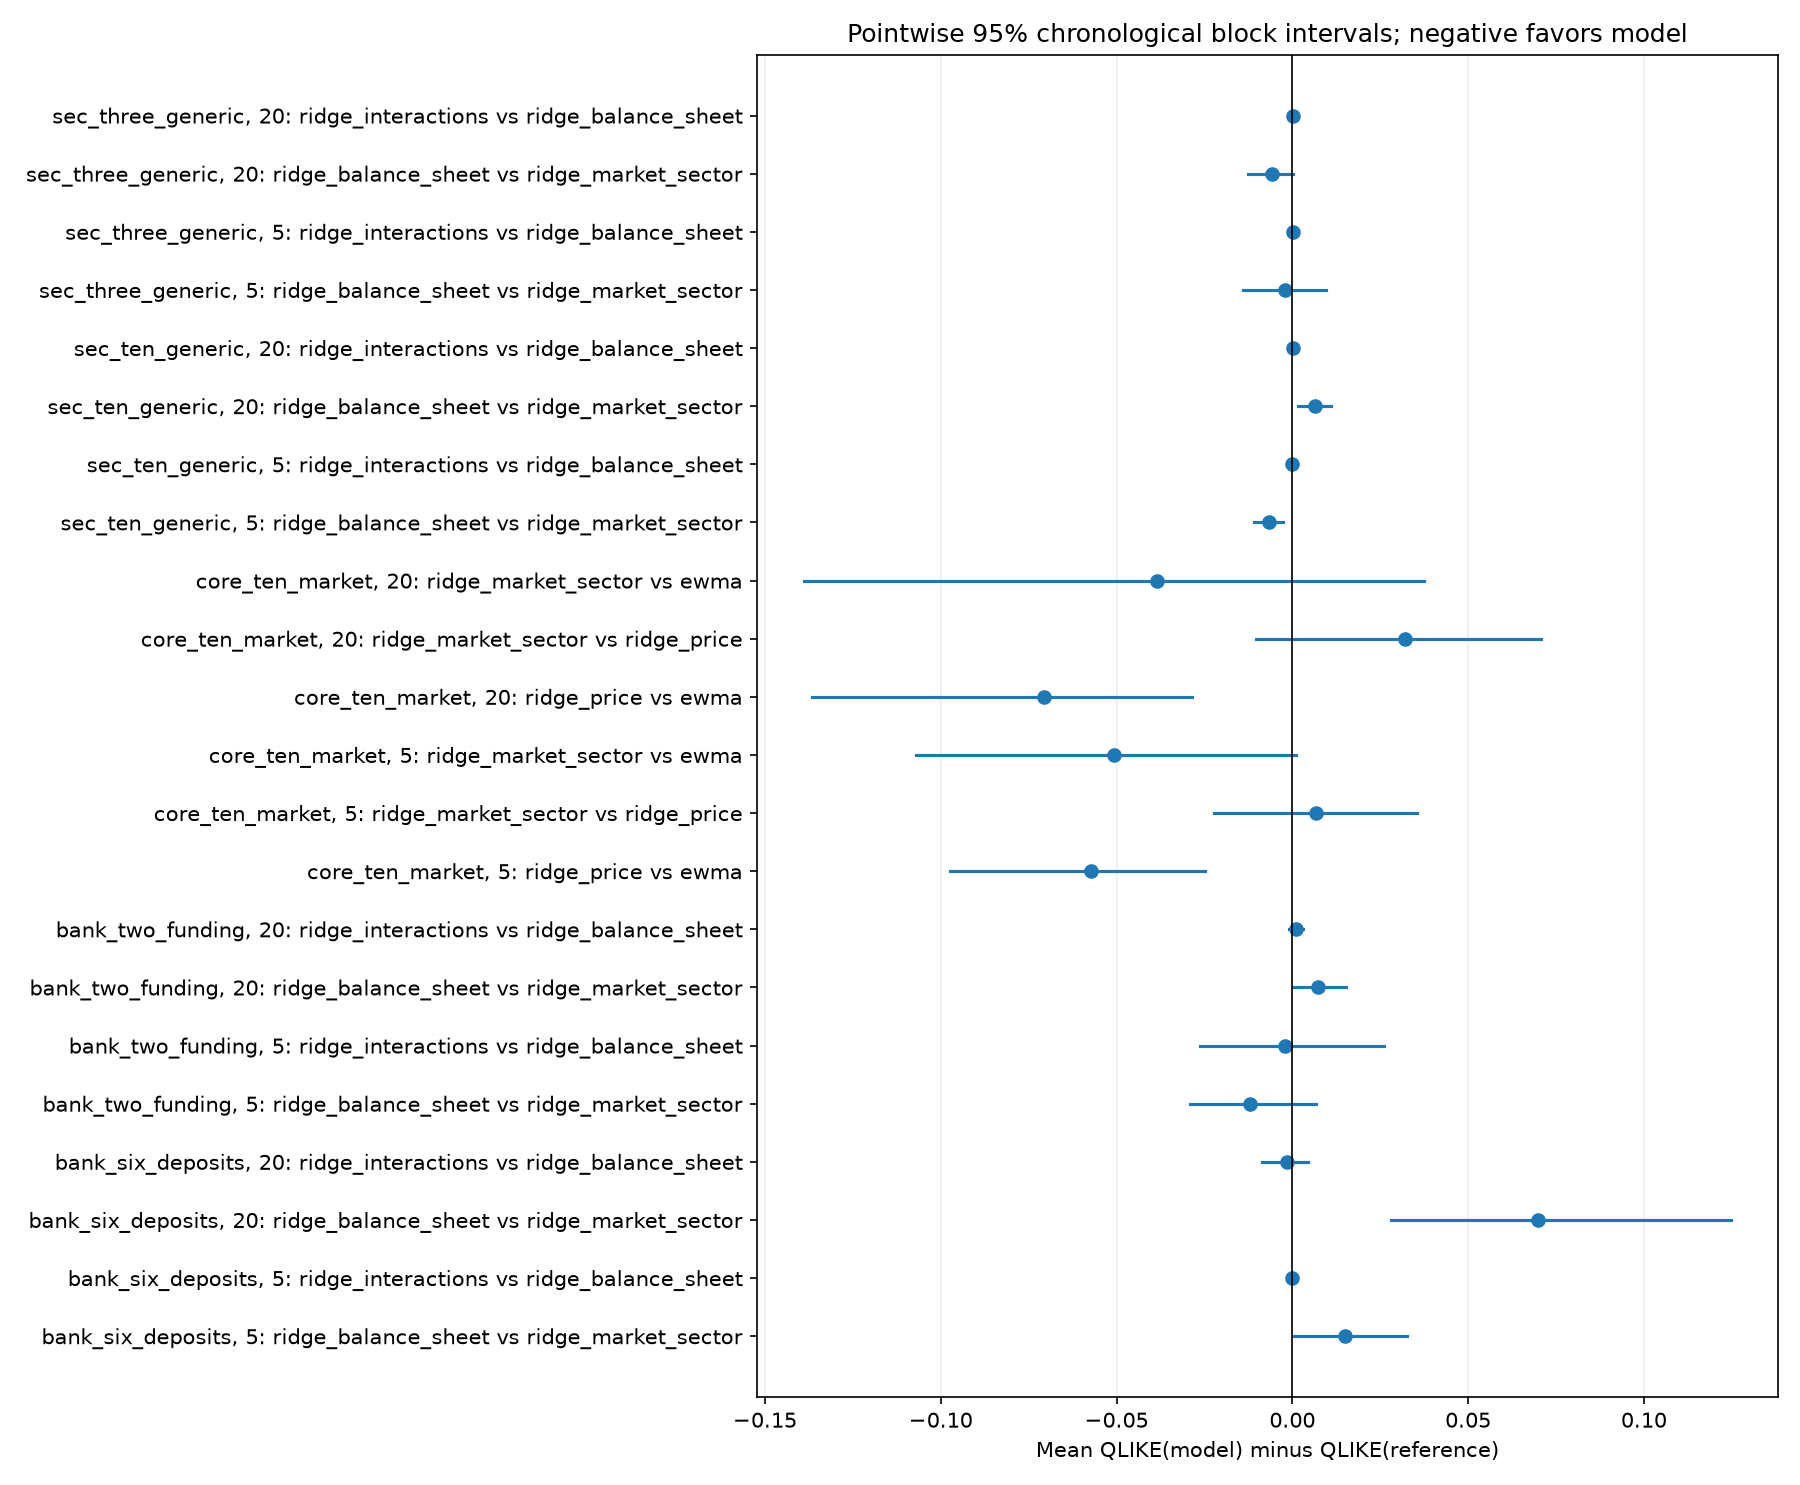

In [5]:
scores = pd.read_csv(output / "scores.csv")
test_scores = scores.loc[scores["split"].eq("test")]
display(test_scores)
intervals = pd.read_csv(output / "paired_loss_differences.csv")
incremental = intervals.loc[
    intervals["split"].eq("test") & intervals["metric"].eq("qlike")
    & intervals["left_model"].isin(["ridge_balance_sheet", "ridge_interactions"])
    & intervals["reference"].isin(["ridge_market_sector", "ridge_balance_sheet"])
]
display(incremental[["cohort", "horizon", "left_model", "reference", "estimate", "lower", "upper", "n_dates", "block_length"]])
display(Image(filename=str(output / "test_qlike_intervals.png")))



## Verify the financial availability trace

The trace records actual matched release bounds and fiscal periods for each issuer/origin/horizon. A release must not arrive after the decision cutoff, and old fiscal information cannot become fresh merely because it was quoted again in a later filing.

In [6]:
trace = pd.read_csv(output / "financial_availability_trace.csv")
display(trace.head(12))
checks = json.loads((output / "checks.json").read_text())
display(pd.Series(checks).to_frame("value"))


,cohort,asset,origin,origin_at,horizon,split,available_at,matched_period_end,liabilities_assets,bank_deposits_liabilities,bank_cash_assets
0,sec_three_generic,JPM,2011-01-03,2011-01-03 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
1,sec_three_generic,JPM,2011-01-10,2011-01-10 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
2,sec_three_generic,JPM,2011-01-18,2011-01-18 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
3,sec_three_generic,JPM,2011-01-25,2011-01-25 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
4,sec_three_generic,JPM,2011-02-01,2011-02-01 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
5,sec_three_generic,JPM,2011-02-08,2011-02-08 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
6,sec_three_generic,JPM,2011-02-15,2011-02-15 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
7,sec_three_generic,JPM,2011-02-23,2011-02-23 21:00:00+00:00,5,train,2010-11-10 21:00:00+00:00,2010-09-30,0.918832,NaN,NaN
8,sec_three_generic,JPM,2011-03-02,2011-03-02 21:00:00+00:00,5,train,2011-03-01 21:00:00+00:00,2010-12-31,0.916837,NaN,NaN
9,sec_three_generic,JPM,2011-03-09,2011-03-09 21:00:00+00:00,5,train,2011-03-01 21:00:00+00:00,2010-12-31,0.916837,NaN,NaN


,value
models_locked_before_test_predictions,True
fit_scaler_training_only,True
training_targets_purged_before_validation,True
validation_targets_purged_before_test,True
nonoverlap_targets_with_date_clustered_uncertainty,True
test_hyperparameters_tuned,False
total_underlying_variance_target,True
official_SEC_balance_sheet_layer_tested,True
original_vintage_publication_bound_used,True
actual_acceptance_timestamps_claimed,False


## Research interpretation

The generated report retains mixed and negative findings. A small generic balance-sheet improvement at one horizon does not imply improvement at the other horizon, universal bank-funding value, causal identification or derivative-hedging value. Deposits/liabilities and cash-due-from-banks/assets are accounting proxies, not regulatory capital, LCR or insured-deposit measures.

Full vintage-aware macro history, broader original-archive checks, historical universe eligibility and a properly timed forecast-to-overlay experiment remain separate requirements. Do not automatically delta-neutralize protective options or replace pricing volatility with a physical-risk forecast.